In [4]:
from pathlib import Path

RAW_DIR = Path(r"C:\Cricket_Prediction\data\raw")

print("Folder exists:", RAW_DIR.exists())

if RAW_DIR.exists():
    print("Items inside raw:", list(RAW_DIR.iterdir()))

    json_files = list(RAW_DIR.rglob("*.json"))
    print("Total JSON files:", len(json_files))
    print("First 10 files:", [f.name for f in json_files[:10]])

Folder exists: True
Items inside raw: [WindowsPath('C:/Cricket_Prediction/data/raw/1082591.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082592.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082593.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082594.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082595.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082596.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082597.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082598.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082599.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082600.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082601.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082602.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082603.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082604.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082605.json'), WindowsPath('C:/Cricket_Prediction/data/raw/1082606.json'), W

In [5]:

import sys
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Cricket_Prediction")
RAW_DIR = PROJECT_ROOT / "data" / "raw"

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data_loader import load_ipl_data

raw_df = load_ipl_data(RAW_DIR)

print("Total deliveries:", len(raw_df))
print("Unique matches:", raw_df["match_id"].nunique())
print("Unique batters:", raw_df["batter"].nunique())

display(raw_df.head())


Total deliveries: 295732
Unique matches: 1243
Unique batters: 738


,match_id,date,venue,innings,over,delivery_index,batter,bowler,batter_runs,total_runs,extras,is_wide,is_no_ball,dismissed_players,wicket_types
0,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0,1,DA Warner,TS Mills,0,0,{},False,False,[],[]
1,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0,2,DA Warner,TS Mills,0,0,{},False,False,[],[]
2,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0,3,DA Warner,TS Mills,4,4,{},False,False,[],[]
3,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0,4,DA Warner,TS Mills,0,0,{},False,False,[],[]
4,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0,5,DA Warner,TS Mills,0,2,{'wides': 2},True,False,[],[]


In [6]:

from feature_engineering import prepare_batting_data

faced_df = prepare_batting_data(raw_df)

print("Rows after excluding wides:", len(faced_df))
print("Unique batter innings:", faced_df["batter_innings_id"].nunique())

display(
    faced_df[
        [
            "match_id",
            "innings",
            "batter",
            "bowler",
            "over",
            "ball_faced_number",
            "batter_runs",
            "phase",
            "dismissed"
        ]
    ].head(20)
)


Rows after excluding wides: 285856
Unique batter innings: 18837


,match_id,innings,batter,bowler,over,ball_faced_number,batter_runs,phase,dismissed
0,1082591,1,DA Warner,TS Mills,0,1,0,Powerplay,False
1,1082591,1,DA Warner,TS Mills,0,2,0,Powerplay,False
2,1082591,1,DA Warner,TS Mills,0,3,4,Powerplay,False
3,1082591,1,DA Warner,TS Mills,0,4,0,Powerplay,False
5,1082591,1,S Dhawan,TS Mills,0,1,0,Powerplay,False
6,1082591,1,S Dhawan,TS Mills,0,2,0,Powerplay,False
7,1082591,1,S Dhawan,A Choudhary,1,3,1,Powerplay,False
8,1082591,1,DA Warner,A Choudhary,1,5,4,Powerplay,False
9,1082591,1,DA Warner,A Choudhary,1,6,0,Powerplay,False
10,1082591,1,DA Warner,A Choudhary,1,7,6,Powerplay,False


In [7]:
sample = faced_df[
    faced_df["batter_innings_id"]
    == faced_df["batter_innings_id"].iloc[0]
]

display(
    sample[
        ["batter", "over", "delivery_index", "ball_faced_number"]
    ].head(20)
)

assert sample["ball_faced_number"].is_monotonic_increasing
assert sample["ball_faced_number"].iloc[0] >= 1

print("Basic validation passed.")

,batter,over,delivery_index,ball_faced_number
0,DA Warner,0,1,1
1,DA Warner,0,2,2
2,DA Warner,0,3,3
3,DA Warner,0,4,4
8,DA Warner,1,2,5
9,DA Warner,1,3,6
10,DA Warner,1,4,7
11,DA Warner,1,5,8


Basic validation passed.


In [8]:

from analysis import calculate_ball_metrics, calculate_phase_metrics

ball_metrics = calculate_ball_metrics(faced_df)
phase_metrics = calculate_phase_metrics(faced_df)

print("Overall ball metrics:")
display(ball_metrics.head(15))

print("Phase metrics:")
display(phase_metrics.head(10))


Overall ball metrics:


,ball_faced_number,batter_innings,dismissals,total_runs,balls,dismissal_rate_pct,strike_rate,strike_rate_smooth
0,1,18837,759,15514,18837,4.029304,82.359187,82.359187
1,2,17526,749,17391,17526,4.273651,99.229716,90.794451
2,3,16359,745,17772,16359,4.554068,108.637447,96.742117
3,4,15302,704,17804,15302,4.600706,116.350804,101.644288
4,5,14358,662,17670,14358,4.610670,123.067280,105.928887
5,6,13456,606,17042,13456,4.503567,126.649822,114.787014
6,7,12630,654,17001,12630,5.178147,134.608076,121.862686
7,8,11785,597,16065,11785,5.065762,136.317353,127.398667
8,9,11031,588,15226,11031,5.330432,138.029190,131.734344
9,10,10305,493,14758,10305,4.784085,143.212033,135.763295


Phase metrics:


,phase,ball_faced_number,batter_innings,dismissals,total_runs,balls,dismissal_rate_pct,strike_rate
0,Powerplay,1,8451,244,6441,8451,2.887232,76.215832
1,Powerplay,2,7986,252,7584,7986,3.155522,94.966191
2,Powerplay,3,7518,263,8009,7518,3.498271,106.530992
3,Powerplay,4,7047,250,8124,7047,3.547609,115.283099
4,Powerplay,5,6592,240,8080,6592,3.640777,122.572816
5,Powerplay,6,6150,226,7874,6150,3.674797,128.032520
6,Powerplay,7,5730,270,7714,5730,4.712042,134.624782
7,Powerplay,8,5282,220,7428,5282,4.165089,140.628550
8,Powerplay,9,4890,225,6916,4890,4.601227,141.431493
9,Powerplay,10,4511,190,6720,4511,4.211926,148.969186


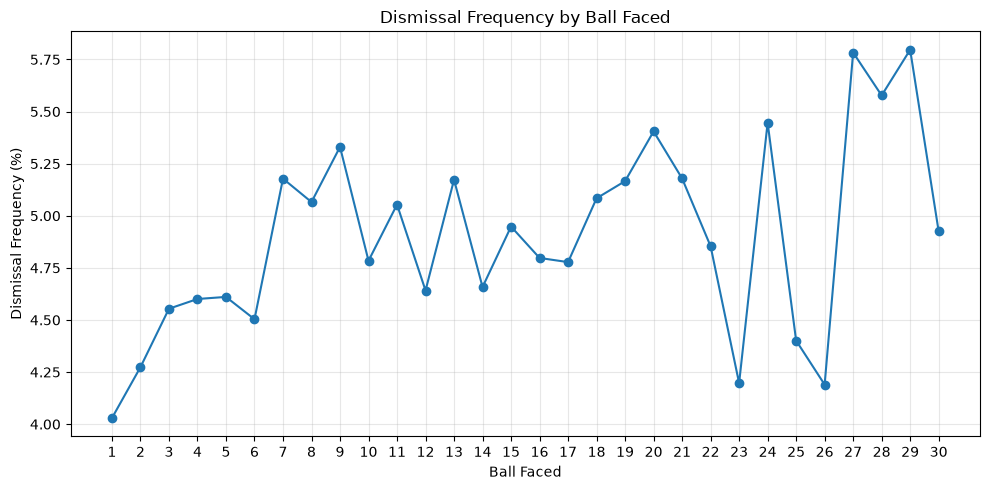

In [9]:
import matplotlib.pyplot as plt

plot_data = ball_metrics[
    (ball_metrics["ball_faced_number"] <= 30)
    & (ball_metrics["batter_innings"] >= 50)
]

plt.figure(figsize=(10, 5))

plt.plot(
    plot_data["ball_faced_number"],
    plot_data["dismissal_rate_pct"],
    marker="o"
)

plt.title("Dismissal Frequency by Ball Faced")
plt.xlabel("Ball Faced")
plt.ylabel("Dismissal Frequency (%)")
plt.xticks(range(1, 31))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

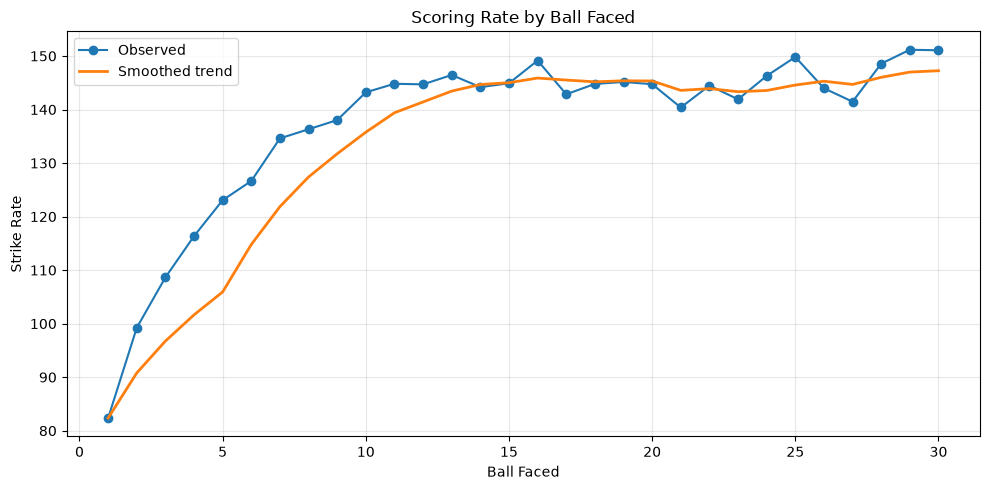

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    plot_data["ball_faced_number"],
    plot_data["strike_rate"],
    marker="o",
    label="Observed"
)

plt.plot(
    plot_data["ball_faced_number"],
    plot_data["strike_rate_smooth"],
    linewidth=2,
    label="Smoothed trend"
)

plt.title("Scoring Rate by Ball Faced")
plt.xlabel("Ball Faced")
plt.ylabel("Strike Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:

from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r"C:\Cricket_Prediction")
RAW_DIR = PROJECT_ROOT / "data" / "raw"
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data_loader import load_ipl_data
from feature_engineering import prepare_batting_data
from analysis import calculate_ball_metrics, calculate_phase_metrics

# Load the IPL JSON files
raw_df = load_ipl_data(RAW_DIR)

# Prepare batter-level data
faced_df = prepare_batting_data(raw_df)

# Calculate analysis metrics
ball_metrics = calculate_ball_metrics(faced_df)
phase_metrics = calculate_phase_metrics(faced_df)

print("Dataset loaded successfully!")
print("Total deliveries:", len(raw_df))
print("Balls faced:", len(faced_df))
print("Batter innings:", faced_df["batter_innings_id"].nunique())

display(ball_metrics.head())


Dataset loaded successfully!
Total deliveries: 295732
Balls faced: 285856
Batter innings: 18837


,ball_faced_number,batter_innings,dismissals,total_runs,balls,dismissal_rate_pct,strike_rate,strike_rate_smooth
0,1,18837,759,15514,18837,4.029304,82.359187,82.359187
1,2,17526,749,17391,17526,4.273651,99.229716,90.794451
2,3,16359,745,17772,16359,4.554068,108.637447,96.742117
3,4,15302,704,17804,15302,4.600706,116.350804,101.644288
4,5,14358,662,17670,14358,4.610670,123.067280,105.928887


In [5]:
from regression_models import fit_regression_models

sr_results, sr_curve = fit_regression_models(
    ball_metrics,
    "strike_rate"
)

display(sr_results)

,Model,R2,RMSE
0,Linear Regression,0.855916,9.695120
1,Polynomial Regression,0.856620,9.671409


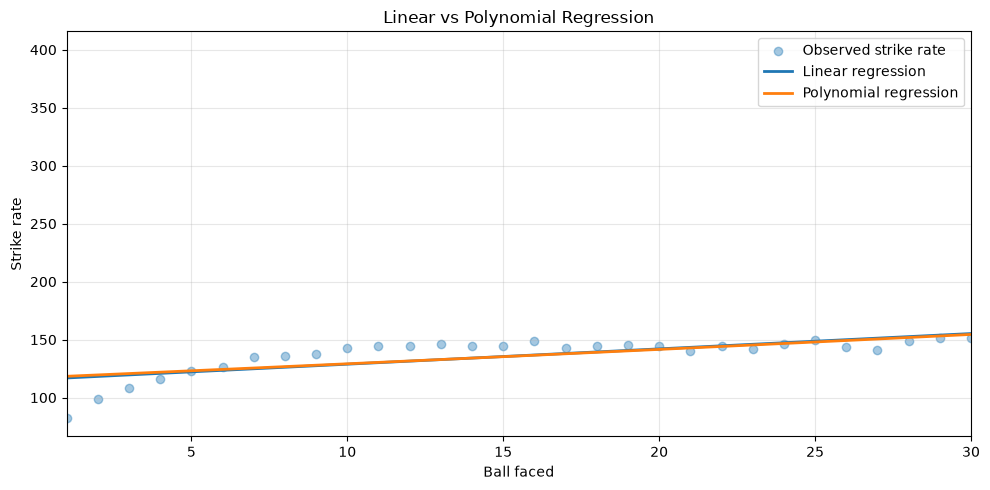

In [6]:

plt.figure(figsize=(10, 5))

plt.scatter(
    ball_metrics["ball_faced_number"],
    ball_metrics["strike_rate"],
    alpha=0.4,
    label="Observed strike rate"
)

plt.plot(
    sr_curve["ball_faced_number"],
    sr_curve["Linear"],
    linewidth=2,
    label="Linear regression"
)

plt.plot(
    sr_curve["ball_faced_number"],
    sr_curve["Polynomial"],
    linewidth=2,
    label="Polynomial regression"
)

plt.xlim(1, 30)
plt.xlabel("Ball faced")
plt.ylabel("Strike rate")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


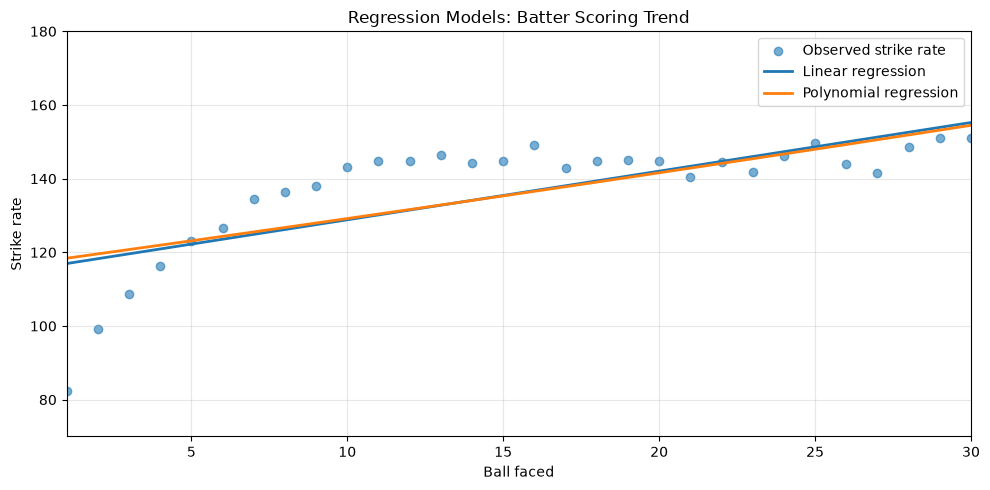

In [7]:
plt.figure(figsize=(10, 5))

plot_data = ball_metrics[
    (ball_metrics["ball_faced_number"] <= 30)
    & (ball_metrics["batter_innings"] >= 50)
]

plt.scatter(
    plot_data["ball_faced_number"],
    plot_data["strike_rate"],
    alpha=0.6,
    label="Observed strike rate"
)

plt.plot(
    sr_curve["ball_faced_number"],
    sr_curve["Linear"],
    label="Linear regression",
    linewidth=2
)

plt.plot(
    sr_curve["ball_faced_number"],
    sr_curve["Polynomial"],
    label="Polynomial regression",
    linewidth=2
)

plt.xlim(1, 30)
plt.ylim(70, 180)
plt.xlabel("Ball faced")
plt.ylabel("Strike rate")
plt.title("Regression Models: Batter Scoring Trend")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
from importlib import reload
import regression_models

reload(regression_models)

sr_results, sr_curve = regression_models.fit_regression_models(
    ball_metrics,
    "strike_rate"
)

display(sr_results)

,Model,Test R2,Test RMSE
0,Linear Regression,0.816325,13.354656
1,Polynomial Regression,0.817359,13.317013


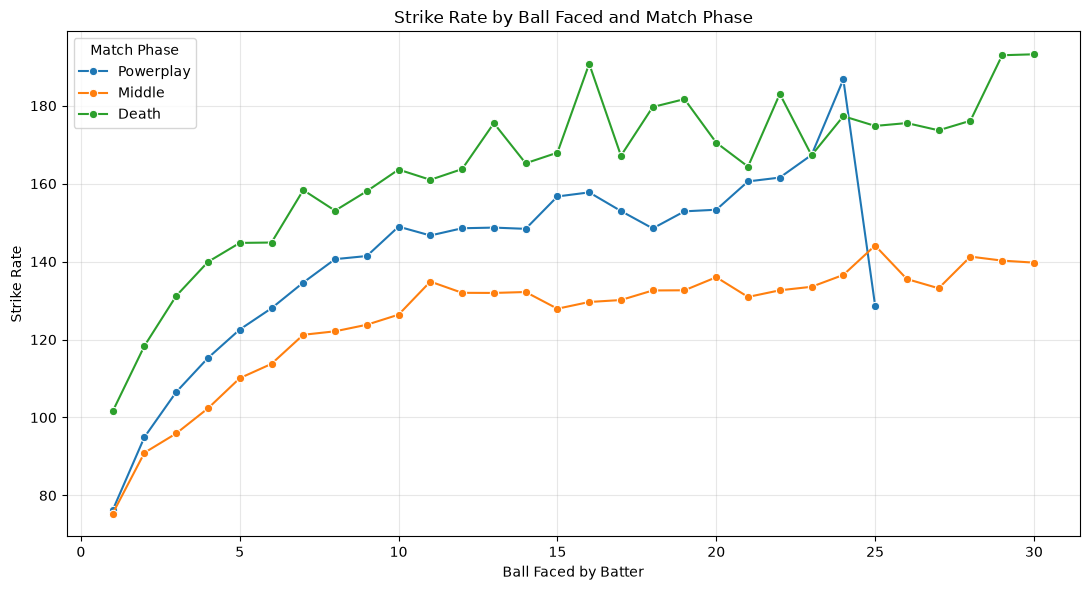

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

phase_plot = phase_metrics[
    (phase_metrics["ball_faced_number"] <= 30)
    & (phase_metrics["batter_innings"] >= 50)
]

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=phase_plot,
    x="ball_faced_number",
    y="strike_rate",
    hue="phase",
    marker="o"
)

plt.title("Strike Rate by Ball Faced and Match Phase")
plt.xlabel("Ball Faced by Batter")
plt.ylabel("Strike Rate")
plt.legend(title="Match Phase")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
from player_ranking import calculate_eye_in_index

eye_in_results = calculate_eye_in_index(
    faced_df,
    min_balls=100
)

display(eye_in_results.head(15))

,batter,first_10_sr,after_20_sr,first_10_dismissal_pct,after_20_dismissal_pct,scoring_improvement,dismissal_rate_change_pp,first_10_balls,after_20_balls
0,DA Miller,111.300813,192.700730,2.845528,5.839416,81.399917,2.993888,1230.0,411.0
1,LS Livingstone,128.457447,206.569343,5.851064,5.839416,78.111896,-0.011648,376.0,137.0
2,SR Watson,103.700658,178.033981,3.453947,5.218447,74.333323,1.764499,1216.0,824.0
3,CL White,102.240896,174.479167,4.201681,5.208333,72.238270,1.006653,357.0,192.0
4,AD Russell,149.944994,222.043011,5.060506,6.451613,72.098016,1.391107,909.0,186.0
5,AB de Villiers,121.038062,192.204042,3.529412,4.138595,71.165980,0.609183,1445.0,1039.0
6,SP Narine,149.315068,218.181818,9.041096,7.575758,68.866750,-1.465338,730.0,132.0
7,SO Hetmyer,131.578947,200.000000,4.385965,7.692308,68.421053,3.306343,684.0,104.0
8,RS Bopara,85.263158,152.413793,2.631579,4.827586,67.150635,2.196007,190.0,145.0
9,C Connolly,133.057851,200.000000,2.479339,4.901961,66.942149,2.422622,121.0,102.0


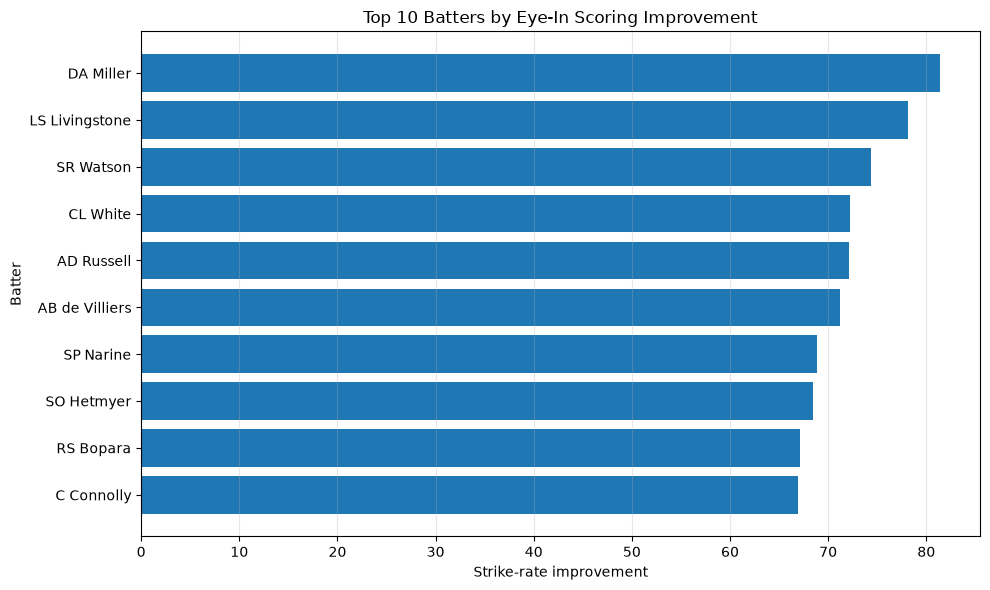

In [12]:

import matplotlib.pyplot as plt

# Calculate improvement explicitly.
eye_in_results["scoring_improvement"] = (
    eye_in_results["after_20_sr"]
    - eye_in_results["first_10_sr"]
)

top_10 = eye_in_results.nlargest(
    10, "scoring_improvement"
).sort_values("scoring_improvement")

plt.figure(figsize=(10, 6))

plt.barh(
    top_10["batter"],
    top_10["scoring_improvement"]
)

plt.xlabel("Strike-rate improvement")
plt.ylabel("Batter")
plt.title("Top 10 Batters by Eye-In Scoring Improvement")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:
print("Number of ranked batters:", len(eye_in_results))

display(
    eye_in_results[
        [
            "batter",
            "first_10_balls",
            "after_20_balls",
            "first_10_sr",
            "after_20_sr",
            "scoring_improvement"
        ]
    ].head(10)
)

Number of ranked batters: 130


,batter,first_10_balls,after_20_balls,first_10_sr,after_20_sr,scoring_improvement
0,DA Miller,1230.0,411.0,111.300813,192.700730,81.399917
1,LS Livingstone,376.0,137.0,128.457447,206.569343,78.111896
2,SR Watson,1216.0,824.0,103.700658,178.033981,74.333323
3,CL White,357.0,192.0,102.240896,174.479167,72.238270
4,AD Russell,909.0,186.0,149.944994,222.043011,72.098016
5,AB de Villiers,1445.0,1039.0,121.038062,192.204042,71.165980
6,SP Narine,730.0,132.0,149.315068,218.181818,68.866750
7,SO Hetmyer,684.0,104.0,131.578947,200.000000,68.421053
8,RS Bopara,190.0,145.0,85.263158,152.413793,67.150635
9,C Connolly,121.0,102.0,133.057851,200.000000,66.942149


In [14]:
player = faced_df[faced_df["batter"] == "DA Miller"].copy()

first_10 = player[player["ball_faced_number"] <= 10]
after_20 = player[player["ball_faced_number"] > 20]

print("First-10-ball innings:",
      first_10["batter_innings_id"].nunique())

print("Innings reaching beyond ball 20:",
      after_20["batter_innings_id"].nunique())

First-10-ball innings: 144
Innings reaching beyond ball 20: 41


In [2]:
import sys
import importlib

sys.path.insert(0, r"C:\Cricket_Prediction\src")

import confidence_intervals

importlib.reload(confidence_intervals)

from confidence_intervals import bootstrap_eye_in

print("Bootstrap function imported successfully!")

Bootstrap function imported successfully!


In [4]:

from pathlib import Path
import sys

PROJECT_ROOT = Path(r"C:\Cricket_Prediction")
SRC_DIR = PROJECT_ROOT / "src"
RAW_DIR = PROJECT_ROOT / "data" / "raw"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data_loader import load_ipl_data
from feature_engineering import prepare_batting_data

raw_df = load_ipl_data(RAW_DIR)
faced_df = prepare_batting_data(raw_df)

print("Data loaded successfully!")
print("Total deliveries:", len(raw_df))
print("Balls faced:", len(faced_df))
print("Batter innings:", faced_df["batter_innings_id"].nunique())


Data loaded successfully!
Total deliveries: 295732
Balls faced: 285856
Batter innings: 18837


In [5]:
from confidence_intervals import bootstrap_eye_in

result = bootstrap_eye_in(
    faced_df,
    "DA Miller",
    n_bootstrap=1000,
    random_state=42
)

print("Batter:", result["batter"])
print("First-period innings:", result["first_period_innings"])
print("Later-period innings:", result["later_period_innings"])
print(f"Scoring improvement: {result['improvement']:.2f}")
print(
    f"95% confidence interval: "
    f"{result['ci_lower']:.2f} to {result['ci_upper']:.2f}"
)

Batter: DA Miller
First-period innings: 144
Later-period innings: 41
Scoring improvement: 81.40
95% confidence interval: 55.56 to 106.66


In [7]:

import sys
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Cricket_Prediction")
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from player_ranking import calculate_eye_in_index

eye_in_results = calculate_eye_in_index(
    faced_df,
    min_balls=100
)

print("Rankings recreated:", len(eye_in_results))
display(eye_in_results.head(10))


Rankings recreated: 130


,batter,first_10_sr,after_20_sr,first_10_dismissal_pct,after_20_dismissal_pct,scoring_improvement,dismissal_rate_change_pp,first_10_balls,after_20_balls
0,DA Miller,111.300813,192.700730,2.845528,5.839416,81.399917,2.993888,1230.0,411.0
1,LS Livingstone,128.457447,206.569343,5.851064,5.839416,78.111896,-0.011648,376.0,137.0
2,SR Watson,103.700658,178.033981,3.453947,5.218447,74.333323,1.764499,1216.0,824.0
3,CL White,102.240896,174.479167,4.201681,5.208333,72.238270,1.006653,357.0,192.0
4,AD Russell,149.944994,222.043011,5.060506,6.451613,72.098016,1.391107,909.0,186.0
5,AB de Villiers,121.038062,192.204042,3.529412,4.138595,71.165980,0.609183,1445.0,1039.0
6,SP Narine,149.315068,218.181818,9.041096,7.575758,68.866750,-1.465338,730.0,132.0
7,SO Hetmyer,131.578947,200.000000,4.385965,7.692308,68.421053,3.306343,684.0,104.0
8,RS Bopara,85.263158,152.413793,2.631579,4.827586,67.150635,2.196007,190.0,145.0
9,C Connolly,133.057851,200.000000,2.479339,4.901961,66.942149,2.422622,121.0,102.0


In [8]:

from confidence_intervals import bootstrap_eye_in
import pandas as pd

top_batters = eye_in_results.head(10)["batter"].tolist()

bootstrap_results = []

for batter in top_batters:
    try:
        result = bootstrap_eye_in(
            faced_df,
            batter,
            n_bootstrap=1000,
            random_state=42
        )
        bootstrap_results.append(result)

    except ValueError as error:
        print(f"Skipping {batter}: {error}")

bootstrap_df = pd.DataFrame(bootstrap_results)

display(
    bootstrap_df[
        [
            "batter",
            "first_period_innings",
            "later_period_innings",
            "improvement",
            "ci_lower",
            "ci_upper"
        ]
    ].sort_values("improvement", ascending=False)
)


Skipping RS Bopara: Insufficient innings for reliable bootstrap analysis.
Skipping C Connolly: Insufficient innings for reliable bootstrap analysis.


,batter,first_period_innings,later_period_innings,improvement,ci_lower,ci_upper
0,DA Miller,144,41,81.399917,55.560228,106.658734
1,LS Livingstone,49,11,78.111896,45.010264,111.560820
2,SR Watson,143,55,74.333323,57.995306,90.896421
3,CL White,46,15,72.238270,45.241690,97.206730
4,AD Russell,115,24,72.098016,25.553590,116.849340
5,AB de Villiers,172,75,71.165980,53.865326,89.527398
6,SP Narine,122,10,68.866750,37.830600,98.636768
7,SO Hetmyer,86,14,68.421053,29.273573,102.727754


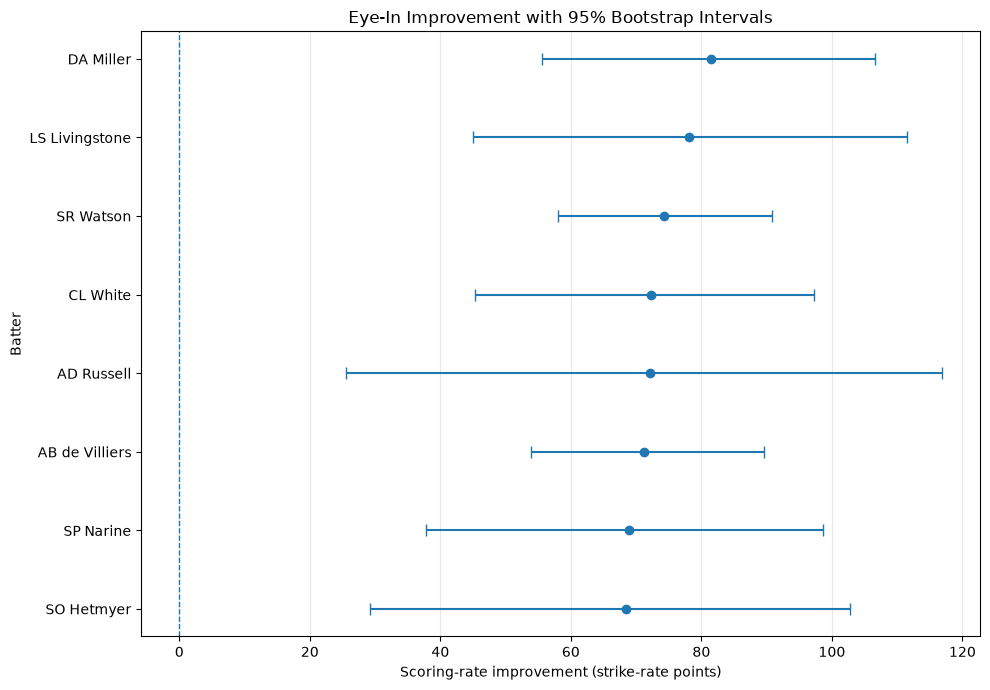

In [9]:

import matplotlib.pyplot as plt

plot_df = bootstrap_df.sort_values("improvement").copy()

lower_error = (
    plot_df["improvement"] - plot_df["ci_lower"]
).clip(lower=0)

upper_error = (
    plot_df["ci_upper"] - plot_df["improvement"]
).clip(lower=0)

plt.figure(figsize=(10, 7))

plt.errorbar(
    plot_df["improvement"],
    plot_df["batter"],
    xerr=[lower_error, upper_error],
    fmt="o",
    capsize=4
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel("Scoring-rate improvement (strike-rate points)")
plt.ylabel("Batter")
plt.title("Eye-In Improvement with 95% Bootstrap Intervals")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

print("Raw dataset columns:")
print(raw_df.columns.tolist())

print("\nProcessed dataset columns:")
print(faced_df.columns.tolist())

print("\nDismissal column preview:")
if "dismissed" in faced_df.columns:
    print(faced_df["dismissed"].value_counts(dropna=False))
else:
    print("No 'dismissed' column found.")

print("\nExtra delivery information:")
for col in ["extras_type", "wide", "wides", "dismissal_kind"]:
    if col in raw_df.columns:
        print(f"\n{col}:")
        print(raw_df[col].value_counts(dropna=False).head(10))


Raw dataset columns:
['match_id', 'date', 'venue', 'innings', 'over', 'delivery_index', 'batter', 'bowler', 'batter_runs', 'total_runs', 'extras', 'is_wide', 'is_no_ball', 'dismissed_players', 'wicket_types']

Processed dataset columns:
['match_id', 'date', 'venue', 'innings', 'over', 'delivery_index', 'batter', 'bowler', 'batter_runs', 'total_runs', 'extras', 'is_wide', 'is_no_ball', 'dismissed_players', 'wicket_types', 'innings_id', 'phase', 'counts_as_faced', 'ball_faced_number', 'dismissed', 'batter_innings_id']

Dismissal column preview:
dismissed
False    271772
True      14084
Name: count, dtype: int64

Extra delivery information:


In [11]:


print("RAW COLUMNS:")
for col in raw_df.columns:
    print(col)

print("\nDISMISSAL COUNTS IN PROCESSED DATA:")
print(faced_df["dismissed"].value_counts(dropna=False))

# Inspect rows marked as dismissals
print("\nSAMPLE DISMISSAL ROWS:")
display(
    faced_df.loc[
        faced_df["dismissed"] == True
    ].head(10)
)


RAW COLUMNS:
match_id
date
venue
innings
over
delivery_index
batter
bowler
batter_runs
total_runs
extras
is_wide
is_no_ball
dismissed_players
wicket_types

DISMISSAL COUNTS IN PROCESSED DATA:
dismissed
False    271772
True      14084
Name: count, dtype: int64

SAMPLE DISMISSAL ROWS:


,match_id,date,venue,innings,over,delivery_index,batter,bowler,batter_runs,total_runs,...,is_wide,is_no_ball,dismissed_players,wicket_types,innings_id,phase,counts_as_faced,ball_faced_number,dismissed,batter_innings_id
11,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,1,5,DA Warner,A Choudhary,0,0,...,False,False,[DA Warner],[caught],1082591_1,Powerplay,True,8,True,1082591_1_DA Warner
64,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,10,3,S Dhawan,STR Binny,0,0,...,False,False,[S Dhawan],[caught],1082591_1,Middle,True,31,True,1082591_1_S Dhawan
94,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,15,2,MC Henriques,YS Chahal,0,0,...,False,False,[MC Henriques],[caught],1082591_1,Death,True,37,True,1082591_1_MC Henriques
116,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,18,4,Yuvraj Singh,TS Mills,0,0,...,False,False,[Yuvraj Singh],[bowled],1082591_1,Death,True,27,True,1082591_1_Yuvraj Singh
160,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",2,5,4,Mandeep Singh,Rashid Khan,0,0,...,False,False,[Mandeep Singh],[bowled],1082591_2,Powerplay,True,16,True,1082591_2_Mandeep Singh
165,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",2,6,3,CH Gayle,DJ Hooda,0,0,...,False,False,[CH Gayle],[caught],1082591_2,Middle,True,21,True,1082591_2_CH Gayle
199,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",2,11,4,KM Jadhav,MC Henriques,1,1,...,False,False,[KM Jadhav],[run out],1082591_2,Middle,True,16,True,1082591_2_KM Jadhav
206,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",2,12,5,TM Head,Rashid Khan,0,0,...,False,False,[TM Head],[caught],1082591_2,Middle,True,22,True,1082591_2_TM Head
211,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",2,13,4,Sachin Baby,Bipul Sharma,0,0,...,False,False,[Sachin Baby],[caught],1082591_2,Middle,True,3,True,1082591_2_Sachin Baby
230,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",2,16,5,STR Binny,B Kumar,0,0,...,False,False,[STR Binny],[caught],1082591_2,Death,True,10,True,1082591_2_STR Binny


In [12]:

possible_cols = [
    col for col in raw_df.columns
    if any(word in col.lower()
           for word in ["wide", "extra", "dismiss", "kind", "player_out"])
]

print("Relevant raw columns:", possible_cols)

display(raw_df[possible_cols].head(10))

Relevant raw columns: ['extras', 'is_wide', 'dismissed_players']


,extras,is_wide,dismissed_players
0,{},False,[]
1,{},False,[]
2,{},False,[]
3,{},False,[]
4,{'wides': 2},True,[]
5,{},False,[]
6,{'legbyes': 1},False,[]
7,{},False,[]
8,{},False,[]
9,{'noballs': 1},False,[]


In [13]:


raw_df["has_dismissal"] = raw_df["dismissed_players"].apply(
    lambda x: isinstance(x, list) and len(x) > 0
)

print("Total raw deliveries:", len(raw_df))
print("Deliveries with dismissals:", raw_df["has_dismissal"].sum())

print("\nDismissal deliveries on wides:")
print(
    raw_df.loc[
        raw_df["has_dismissal"] & raw_df["is_wide"],
        ["match_id", "innings", "over", "batter",
         "is_wide", "dismissed_players", "wicket_types"]
    ].head(10)
)

print(
    "\nTotal dismissal deliveries on wides:",
    (raw_df["has_dismissal"] & raw_df["is_wide"]).sum()
)


Total raw deliveries: 295732
Deliveries with dismissals: 14705

Dismissal deliveries on wides:
      match_id  innings  over         batter  is_wide dismissed_players  \
371    1082592        1    19      HH Pandya     True      [TG Southee]   
6311   1082617        1     9      YK Pathan     True       [YK Pathan]   
7894   1082625        1     8     KD Karthik     True      [KD Karthik]   
11217  1082639        1    17        WP Saha     True         [WP Saha]   
16805  1136573        2     0         JJ Roy     True          [JJ Roy]   
17077  1136574        2     9  Mandeep Singh     True   [Mandeep Singh]   
23262  1136600        2     2       CH Gayle     True        [CH Gayle]   
29269  1175360        2     6      SR Watson     True       [SR Watson]   
41847  1181766        1    19       DJ Hooda     True        [DJ Hooda]   
41896  1181766        2     7       S Dhawan     True        [S Dhawan]   

      wicket_types  
371      [run out]  
6311     [stumped]  
7894     [stumpe

In [14]:

import sys
import importlib
from pathlib import Path

PROJECT_ROOT = Path(r"C:\Cricket_Prediction")
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import feature_engineering
importlib.reload(feature_engineering)

from feature_engineering import (
    prepare_batting_data,
    prepare_dismissal_events,
)

faced_df = prepare_batting_data(raw_df)
dismissal_events = prepare_dismissal_events(raw_df)

print("Faced-ball rows:", len(faced_df))
print(
    "Unique batter innings:",
    faced_df["batter_innings_id"].nunique()
)
print(
    "Dismissed batters on faced deliveries:",
    faced_df["dismissed"].sum()
)
print(
    "Total dismissal-event deliveries:",
    len(dismissal_events)
)

display(faced_df.head())


Faced-ball rows: 285856
Unique batter innings: 18837
Dismissed batters on faced deliveries: 14084
Total dismissal-event deliveries: 14705


,match_id,date,venue,innings,over,delivery_index,batter,bowler,batter_runs,total_runs,...,is_wide,is_no_ball,dismissed_players,wicket_types,has_dismissal,batter_innings_id,counts_as_ball_faced,ball_faced_number,dismissed,phase
0,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0,1,DA Warner,TS Mills,0,0,...,False,False,[],[],False,1082591_1_DA Warner,True,1,False,Powerplay
1,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0,2,DA Warner,TS Mills,0,0,...,False,False,[],[],False,1082591_1_DA Warner,True,2,False,Powerplay
2,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0,3,DA Warner,TS Mills,4,4,...,False,False,[],[],False,1082591_1_DA Warner,True,3,False,Powerplay
3,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0,4,DA Warner,TS Mills,0,0,...,False,False,[],[],False,1082591_1_DA Warner,True,4,False,Powerplay
4,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0,6,S Dhawan,TS Mills,0,0,...,False,False,[],[],False,1082591_1_S Dhawan,True,1,False,Powerplay


In [15]:

# Compare dismissal events with dismissal types
print("Dismissal types:")
print(raw_df["wicket_types"].explode().value_counts(dropna=False))

print("\nDismissal deliveries on wides:")
wide_dismissals = dismissal_events[
    dismissal_events["is_wide"]
]

print("Wide dismissal deliveries:", len(wide_dismissals))

print("\nDismissed batter versus striker:")
display(
    wide_dismissals[
        [
            "match_id",
            "innings",
            "over",
            "batter",
            "dismissed_players",
            "wicket_types"
        ]
    ].head(15)
)


Dismissal types:
wicket_types
NaN                      281027
caught                     9321
bowled                     2460
run out                    1194
lbw                         883
caught and bowled           410
stumped                     388
hit wicket                   20
retired hurt                 19
retired out                   6
obstructing the field         4
Name: count, dtype: int64

Dismissal deliveries on wides:
Wide dismissal deliveries: 58

Dismissed batter versus striker:


,match_id,innings,over,batter,dismissed_players,wicket_types
21,1082592,1,19,HH Pandya,[TG Southee],[run out]
299,1082617,1,9,YK Pathan,[YK Pathan],[stumped]
387,1082625,1,8,KD Karthik,[KD Karthik],[stumped]
563,1082639,1,17,WP Saha,[WP Saha],[stumped]
865,1136573,2,0,JJ Roy,[JJ Roy],[stumped]
883,1136574,2,9,Mandeep Singh,[Mandeep Singh],[stumped]
1191,1136600,2,2,CH Gayle,[CH Gayle],[stumped]
1488,1175360,2,6,SR Watson,[SR Watson],[stumped]
2080,1181766,1,19,DJ Hooda,[DJ Hooda],[run out]
2082,1181766,2,7,S Dhawan,[S Dhawan],[stumped]


In [16]:

import importlib
import analysis

importlib.reload(analysis)

from analysis import (
    calculate_ball_metrics,
    calculate_phase_metrics,
    summarize_wide_dismissals,
)

ball_metrics = calculate_ball_metrics(
    faced_df,
    min_innings=50
)

phase_metrics = calculate_phase_metrics(
    faced_df,
    min_innings=50
)

wide_dismissals = summarize_wide_dismissals(raw_df)

print("Ball metrics:", ball_metrics.shape)
print("Phase metrics:", phase_metrics.shape)
print("Wide dismissal-event deliveries:", len(wide_dismissals))

display(ball_metrics.head(10))


Ball metrics: (73, 9)
Phase metrics: (162, 9)
Wide dismissal-event deliveries: 58


,ball_faced_number,batter_innings,dismissals,total_runs,balls,dismissal_rate_pct,strike_rate,strike_rate_smooth,enough_data
0,1,18837,759,15514,18837,4.029304,82.359187,82.359187,True
1,2,17526,749,17391,17526,4.273651,99.229716,90.794451,True
2,3,16359,745,17772,16359,4.554068,108.637447,96.742117,True
3,4,15302,704,17804,15302,4.600706,116.350804,101.644288,True
4,5,14358,662,17670,14358,4.610670,123.067280,105.928887,True
5,6,13456,606,17042,13456,4.503567,126.649822,114.787014,True
6,7,12630,654,17001,12630,5.178147,134.608076,121.862686,True
7,8,11785,597,16065,11785,5.065762,136.317353,127.398667,True
8,9,11031,588,15226,11031,5.330432,138.029190,131.734344,True
9,10,10305,493,14758,10305,4.784085,143.212033,135.763295,True


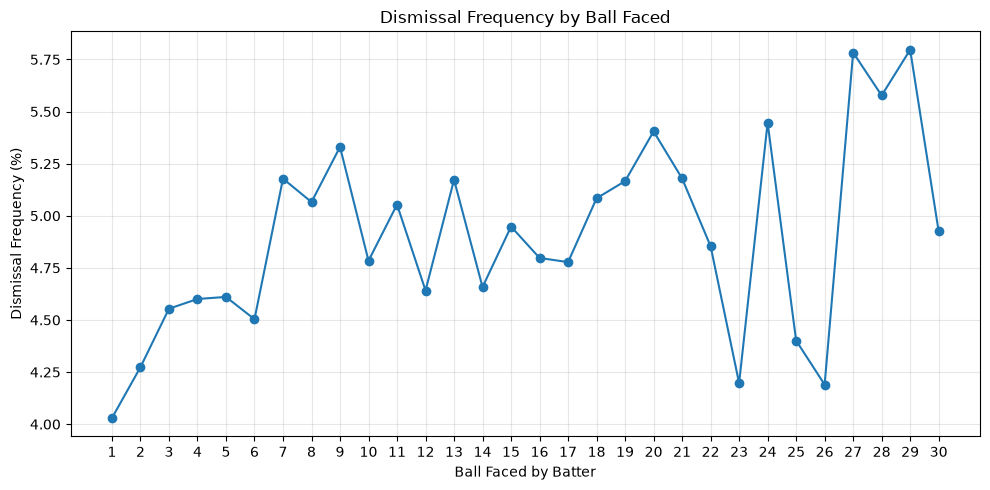

In [17]:

import matplotlib.pyplot as plt

plot_data = ball_metrics[
    (ball_metrics["ball_faced_number"] <= 30)
    & ball_metrics["enough_data"]
]

plt.figure(figsize=(10, 5))

plt.plot(
    plot_data["ball_faced_number"],
    plot_data["dismissal_rate_pct"],
    marker="o",
)

plt.title("Dismissal Frequency by Ball Faced")
plt.xlabel("Ball Faced by Batter")
plt.ylabel("Dismissal Frequency (%)")
plt.xticks(range(1, 31))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

# Check the analysis results before finalizing the project

print("PROJECT VALIDATION")
print("-" * 40)

print("Faced-ball rows:", len(faced_df))
print("Unique batter innings:", faced_df["batter_innings_id"].nunique())
print("Batter dismissals on faced deliveries:", int(faced_df["dismissed"].sum()))
print("Wide dismissal-event deliveries:", len(wide_dismissals))

print("\nRegression results:")
display(sr_results)

print("\nFirst 10 ball metrics:")
display(ball_metrics.head(10))

# Save analysis tables
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

ball_metrics.to_csv(
    output_dir / "ball_metrics.csv", index=False
)

phase_metrics.to_csv(
    output_dir / "phase_metrics.csv", index=False
)

bootstrap_df.to_csv(
    output_dir / "bootstrap_results.csv", index=False
)

print("\nAnalysis tables saved in data/processed/")


PROJECT VALIDATION
----------------------------------------
Faced-ball rows: 285856
Unique batter innings: 18837
Batter dismissals on faced deliveries: 14084
Wide dismissal-event deliveries: 58

Regression results:


NameError: name 'sr_results' is not defined

In [19]:

from pathlib import Path

print("PROJECT VALIDATION")
print("-" * 40)

print("Faced-ball rows:", len(faced_df))
print(
    "Unique batter innings:",
    faced_df["batter_innings_id"].nunique()
)
print(
    "Batter dismissals on faced deliveries:",
    int(faced_df["dismissed"].sum())
)
print(
    "Wide dismissal-event deliveries:",
    len(wide_dismissals)
)

print("\nRegression results:")

if "sr_results" in globals():
    display(sr_results)
else:
    print("Regression results not currently in memory.")
    print("We can recreate them separately.")

print("\nFirst 10 ball metrics:")
display(ball_metrics.head(10))

output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

ball_metrics.to_csv(
    output_dir / "ball_metrics.csv", index=False
)
phase_metrics.to_csv(
    output_dir / "phase_metrics.csv", index=False
)

if "bootstrap_df" in globals():
    bootstrap_df.to_csv(
        output_dir / "bootstrap_results.csv",
        index=False
    )

print("\nAnalysis tables saved in data/processed/")


PROJECT VALIDATION
----------------------------------------
Faced-ball rows: 285856
Unique batter innings: 18837
Batter dismissals on faced deliveries: 14084
Wide dismissal-event deliveries: 58

Regression results:
Regression results not currently in memory.
We can recreate them separately.

First 10 ball metrics:


,ball_faced_number,batter_innings,dismissals,total_runs,balls,dismissal_rate_pct,strike_rate,strike_rate_smooth,enough_data
0,1,18837,759,15514,18837,4.029304,82.359187,82.359187,True
1,2,17526,749,17391,17526,4.273651,99.229716,90.794451,True
2,3,16359,745,17772,16359,4.554068,108.637447,96.742117,True
3,4,15302,704,17804,15302,4.600706,116.350804,101.644288,True
4,5,14358,662,17670,14358,4.610670,123.067280,105.928887,True
5,6,13456,606,17042,13456,4.503567,126.649822,114.787014,True
6,7,12630,654,17001,12630,5.178147,134.608076,121.862686,True
7,8,11785,597,16065,11785,5.065762,136.317353,127.398667,True
8,9,11031,588,15226,11031,5.330432,138.029190,131.734344,True
9,10,10305,493,14758,10305,4.784085,143.212033,135.763295,True



Analysis tables saved in data/processed/
